In [1]:
!pip install numpy==2.2.0
!pip install pandas==2.2.3
!pip install scikit-learn==1.6.0
!pip install matplotlib==3.9.3

  Using cached scikit_learn-1.6.0-cp313-cp313-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (18 kB)
Using cached scikit_learn-1.6.0-cp313-cp313-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (13.2 MB)
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 1.6.1
    Uninstalling scikit-learn-1.6.1:
      Successfully uninstalled scikit-learn-1.6.1
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 27.2 MB/s  0:00:00
  Attempting uninstall: matplotlib
    Found existing installation: matplotlib 3.10.0
    Uninstalling matplotlib-3.10.0:
      Successfully uninstalled matplotlib-3.10.0


In [28]:
import pandas as pd
import numpy as np
%matplotlib inline
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score,r2_score,mean_squared_error,mean_absolute_error,classification_report
import xgboost as xgb
from xgboost import XGBRegressor,XGBClassifier
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import confusion_matrix
import seaborn as sns
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

In [3]:
df=pd.read_csv('/content/master_training_dataset_calibrated.csv')
df.head()

,ISRO_ProductID,OTS_ProductID,Satellite,Sensor,Acquisition_Date,Region_Name,Dominant_Crop,Latitude,Longitude,Spatial_Resolution_m,...,ALLSKY_SFC_SW_DWN,ET0_mm_day,Crop_Kc,Crop_Water_Demand_ETc_mm,Net_Irrigation_Requirement_mm,Standard_Crop,SAR_VH_VV_Ratio,Radar_RVI,NDVI_NDWI_Ratio,Biomass_Synergy
0,259619441,RAW12OCT2025045908010100055PSANSTLC00GTDC,IRS-R2A,AWiFS,10/12/2025,MP Narmada Basin (Soybean/Cotton),Soybean,22.659303,79.366995,56,...,19.46,2.376391,1.05,2.495211,2.495211,Soybean,-7.185543,0.641989,1.833562,10.009811
1,259619441,RAW12OCT2025045908010100055PSANSTLC00GTDC,IRS-R2A,AWiFS,10/12/2025,MP Narmada Basin (Soybean/Cotton),Soybean,22.595806,79.376591,56,...,19.46,2.376391,1.05,2.495211,2.495211,Soybean,-4.755744,1.002674,1.636220,13.980396
2,259619441,RAW12OCT2025045908010100055PSANSTLC00GTDC,IRS-R2A,AWiFS,10/12/2025,MP Narmada Basin (Soybean/Cotton),Soybean,22.674401,79.273944,56,...,19.46,2.376391,1.05,2.495211,2.495211,Soybean,-5.046203,0.953266,1.706738,13.079043
3,259619441,RAW12OCT2025045908010100055PSANSTLC00GTDC,IRS-R2A,AWiFS,10/12/2025,MP Narmada Basin (Soybean/Cotton),Soybean,22.761935,79.365171,56,...,19.46,2.376391,1.05,2.495211,2.495211,Soybean,-6.124337,0.784822,1.828196,11.602115
4,259619441,RAW12OCT2025045908010100055PSANSTLC00GTDC,IRS-R2A,AWiFS,10/12/2025,MP Narmada Basin (Soybean/Cotton),Soybean,22.586217,79.371253,56,...,19.46,2.376391,1.05,2.495211,2.495211,Soybean,-5.268688,0.916569,1.746714,15.990317


In [4]:
df.isnull().sum()

,0
ISRO_ProductID,0
OTS_ProductID,0
Satellite,0
Sensor,0
Acquisition_Date,0
Region_Name,0
Dominant_Crop,0
Latitude,0
Longitude,0
Spatial_Resolution_m,0


In [5]:
crop_mapping={
    'Paddy (Rice)':'Paddy',
    'Paddy (Aman Dhan)':'Paddy',
    'Paddy (Rice Bowl)':'Paddy',
    'Sugarcane':'Sugarcane',
    'Sugarcane/Paddy':'Sugarcane',
    'Soybean':'Soybean',
    'Pulses (Arhar/Gram)':'Pulses',
    'Paddy/Pulses':'Pulses',
    'Oilseeds (Mustard/Sesame)':'Oilseeds',
    'Maize/Paddy':'Maize',
    'Guava/Paddy/Pulses':'Horticulture'
}

df['Standard_Crop']=df['Dominant_Crop'].map(crop_mapping)

df['SAR_VH_VV_Ratio']=df['SAR_VH_Backscatter_dB']-df['SAR_VV_Backscatter_dB']
df['NDVI_NDWI_Ratio']=df['Optical_NDVI']/(df['Moisture_NDWI']+1e-5)

feature_cols=[
    'Reflectance_Green', 'Reflectance_Red', 'Reflectance_NIR', 'Reflectance_SWIR',
    'Optical_NDVI', 'Optical_EVI2', 'Moisture_NDWI', 'NDVI_NDWI_Ratio',
    'SAR_VV_Backscatter_dB', 'SAR_VH_Backscatter_dB', 'SAR_VH_VV_Ratio',
    'Surface_Temperature_C', 'Cumulative_Rainfall_7Day_mm',
    'T2M', 'T2M_MAX', 'T2M_MIN', 'PRECTOTCORR', 'RH2M', 'GWETTOP', 'GWETROOT', 'WS2M', 'ALLSKY_SFC_SW_DWN',
    'ET0_mm_day'
]

X=df[feature_cols].copy().fillna(df[feature_cols].median())
y=df['Standard_Crop']

In [6]:
le_crop=LabelEncoder()
y_crop=le_crop.fit_transform(df['Standard_Crop'])

In [7]:
X_train,X_test, y_train,y_test=train_test_split(X,y_crop,test_size=0.20,random_state=42,stratify=y_crop)

In [8]:
rf_crop=RandomForestClassifier(n_estimators=300,
    max_depth=16,
    min_samples_split=4,
    min_samples_leaf=2,
    max_features='sqrt',
    class_weight='balanced',
    random_state=42)
rf_crop.fit(X_train,y_train)

y_pred_crop=rf_crop.predict(X_test)
print("Crop Type Classification Report")
print(classification_report(y_test,y_pred_crop,target_names=[str(c) for c in le_crop.classes_]))

Crop Type Classification Report
              precision    recall  f1-score   support

    Oilseeds       1.00      1.00      1.00        30
       Paddy       0.92      0.97      0.95       150
      Pulses       1.00      0.97      0.98        30
     Soybean       1.00      0.83      0.91        30
   Sugarcane       0.84      0.68      0.75        60
         nan       0.82      0.88      0.85       120

    accuracy                           0.90       420
   macro avg       0.93      0.89      0.91       420
weighted avg       0.90      0.90      0.90       420



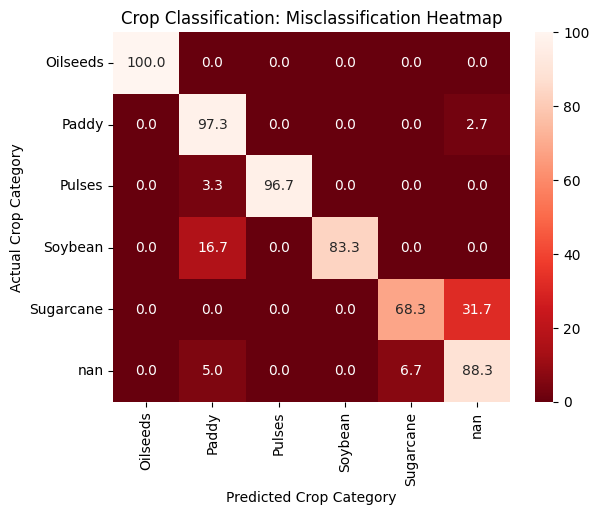

In [9]:
cm=confusion_matrix(y_test,y_pred_crop)
cm_normalized=cm.astype('float')/cm.sum(axis=1)[:,np.newaxis]

sns.heatmap(
    cm_normalized * 100,
    annot=True,
    fmt='.1f',
    cmap='Reds_r',
    xticklabels=le_crop.classes_,
    yticklabels=le_crop.classes_
)
plt.title('Crop Classification: Misclassification Heatmap')
plt.xlabel('Predicted Crop Category')
plt.ylabel('Actual Crop Category')
plt.show()

In [10]:
acc_crop=accuracy_score(y_test,y_pred_crop)
r2_crop=r2_score(y_test,y_pred_crop)
mse_crop=mean_squared_error(y_test,y_pred_crop)

print("Accuracy:",acc_crop);
print("R2 error:",r2_crop);
print("MSE error:",mse_crop);

Accuracy: 0.8976190476190476
R2 error: 0.8520325203252033
MSE error: 0.49523809523809526


In [11]:
y=df['Crop_Water_Stress_Index_CWSI']

In [16]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20,random_state=42)

rfr=RandomForestRegressor(
    n_estimators=150,
    max_depth=10,
    min_samples_split=4,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1)
rfr.fit(X_train,y_train)

RandomForestRegressor(max_depth=10, min_samples_leaf=2, min_samples_split=4,
                      n_estimators=150, n_jobs=-1, random_state=42)

In [19]:
y_pred_train=rfr.predict(X_train)
y_pred_test=rfr.predict(X_test)

train_r2=r2_score(y_train,y_pred_train)
test_r2=r2_score(y_test,y_pred_test)
test_rmse=np.sqrt(mean_squared_error(y_test,y_pred_test))
test_mae=mean_absolute_error(y_test,y_pred_test)

print(f"Train R²:{train_r2:.4f}")
print(f"Test R²:{test_r2:.4f}")
print(f"Test RMSE:{test_rmse:.4f}")
print(f"Test MAE:{test_mae:.4f}")

Train R²:0.9999
Test R²:0.9996
Test RMSE:0.0021
Test MAE:0.0011


In [20]:
importance=rf_crop.feature_importances_

df_imp=pd.DataFrame({'Feature': feature_cols,'Importance': importance})
df_imp=df_imp.sort_values(by='Importance',ascending=True)

df_imp

,Feature,Importance
20,WS2M,0.000000
19,GWETROOT,0.000000
21,ALLSKY_SFC_SW_DWN,0.000000
22,ET0_mm_day,0.000000
18,GWETTOP,0.000000
16,PRECTOTCORR,0.000000
2,Reflectance_NIR,0.007286
5,Optical_EVI2,0.009167
0,Reflectance_Green,0.009675
1,Reflectance_Red,0.010293


Text(0, 0.5, 'Input Variables')

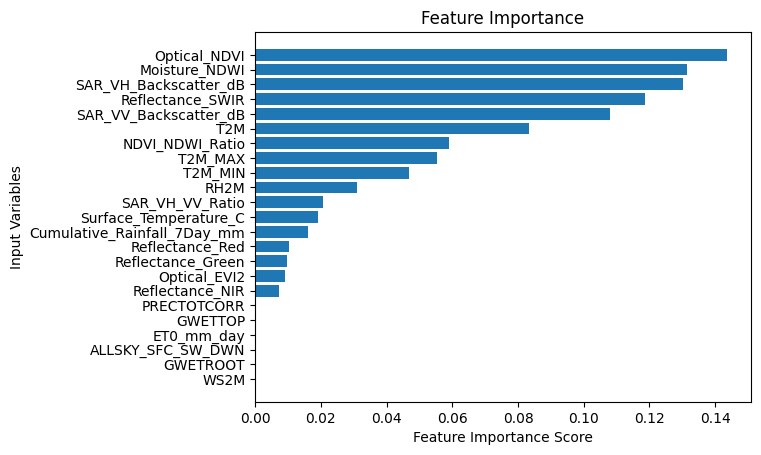

In [21]:
plt.barh(df_imp['Feature'],df_imp['Importance'])
plt.title('Feature Importance')
plt.xlabel('Feature Importance Score')
plt.ylabel('Input Variables')

Text(0, 0.5, 'SAR_VH_Backscatter_dB')

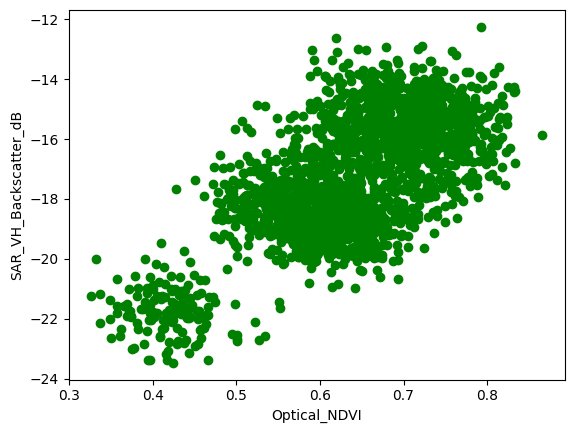

In [22]:
plt.scatter(df['Optical_NDVI'],df['SAR_VH_Backscatter_dB'],color='green')
plt.xlabel('Optical_NDVI')
plt.ylabel('SAR_VH_Backscatter_dB')

In [26]:
X=df[feature_cols]
y=df["Crop_Water_Stress_Index_CWSI"]

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20,random_state=42)

In [29]:
xgb_reg=XGBRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
)

In [30]:
xgb_reg.fit(X_train,y_train)

y_pred_train=xgb_reg.predict(X_train)
y_pred_test=xgb_reg.predict(X_test)

train_r2=r2_score(y_train,y_pred_train)
test_r2=r2_score(y_test,y_pred_test)
test_rmse=np.sqrt(mean_squared_error(y_test,y_pred_test))
test_mae=mean_absolute_error(y_test,y_pred_test)

In [32]:
tolerance_acc=np.mean(np.abs((y_test-y_pred_test)/y_test)<=0.10)*100
mape=np.mean(np.abs((y_test-y_pred_test)/y_test))*100
acc_percentage=max(0.0,100.0-mape)

print(f"Train R²:{train_r2:.4f}")
print(f"Test R²:{test_r2:.4f}")
print(f"Test RMSE:{test_rmse:.4f}")
print(f"Test MAE:{test_mae:.4f}")
print(f"Accuracy:{acc_percentage:.2f}%")
print(f"Within ±10% Tolerance:{tolerance_acc:.2f}%")

Train R²:0.9999
Test R²:0.9995
Test RMSE:0.0022
Test MAE:0.0014
Accuracy:99.68%
Within ±10% Tolerance:100.00%


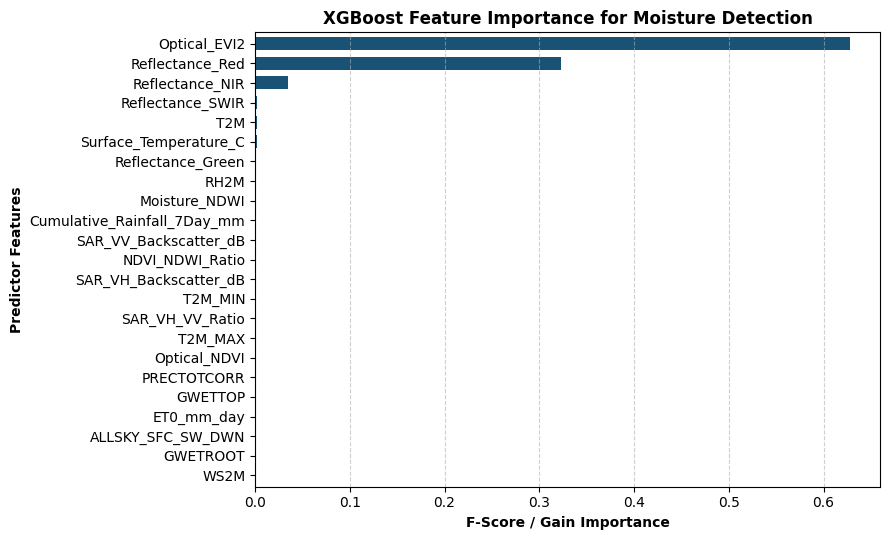

In [39]:
importance = pd.Series(
    xgb_reg.feature_importances_, index=feature_cols
).sort_values(ascending=True)

plt.figure(figsize=(9, 5.5))
importance.plot(kind="barh", color="#1a5276", width=0.65)
plt.title("XGBoost Feature Importance for Moisture Detection", fontweight="bold")
plt.xlabel("F-Score / Gain Importance", fontweight="bold")
plt.ylabel("Predictor Features", fontweight="bold")
plt.grid(axis="x", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

In [40]:
le=LabelEncoder()
y=le.fit_transform(df["Stress_Classification"])

In [41]:
X_train_c,X_test_c,y_train_c,y_test_c =train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)

In [42]:
xgb_clf=XGBClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1,
)

xgb_clf.fit(X_train_c,y_train_c)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='mlogloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=5, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=-1,
              num_parallel_tree=None, ...)

In [43]:
y_pred_class=xgb_clf.predict(X_test_c)
acc=accuracy_score(y_test_c,y_pred_class)

print(f"Test Accuracy:{acc*100:.2f}%\n")
print(classification_report(y_test_c,y_pred_class,target_names=le.classes_))

Test Accuracy:99.05%

                          precision    recall  f1-score   support

Healthy / Well-Irrigated       1.00      0.96      0.98        71
         Moderate Stress       0.99      1.00      0.99       336
     Severe Water Stress       0.93      1.00      0.96        13

                accuracy                           0.99       420
               macro avg       0.97      0.98      0.98       420
            weighted avg       0.99      0.99      0.99       420



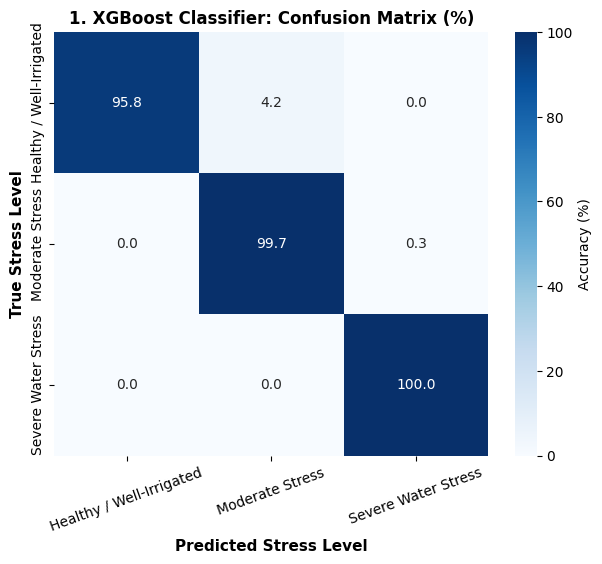

In [50]:
cm=confusion_matrix(y_test_c,y_pred_class,normalize='true')*100

fig,ax1=plt.subplots(figsize=(7, 5.5))

sns.heatmap(cm,annot=True,fmt='.1f',cmap='Blues',xticklabels=le.classes_,yticklabels=le.classes_,cbar_kws={'label':'Accuracy (%)'},ax=ax1)
ax1.set_title("1. XGBoost Classifier: Confusion Matrix (%)",fontsize=12,fontweight='bold')
ax1.set_xlabel("Predicted Stress Level",fontsize=11,fontweight='bold')
ax1.set_ylabel("True Stress Level",fontsize=11,fontweight='bold')
ax1.tick_params(axis='x',rotation=20)

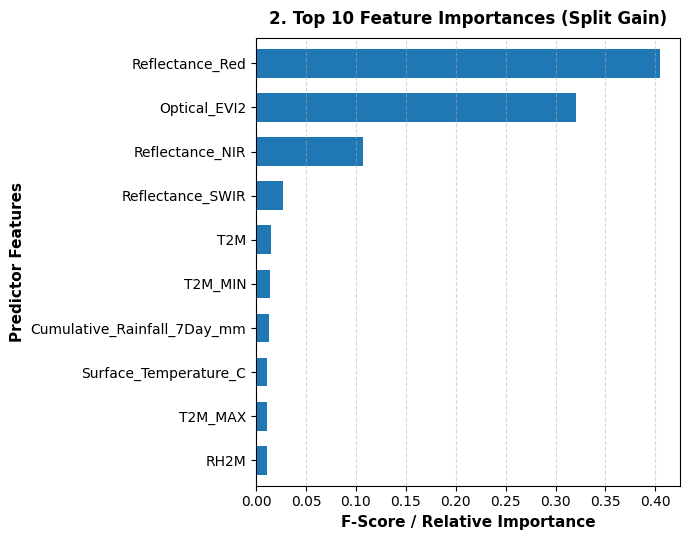

In [57]:
importances = pd.Series(
    xgb_clf.feature_importances_, index=feature_cols
).sort_values(ascending=True)

fig,ax2=plt.subplots(figsize=(7, 5.5))

importances.tail(10).plot(kind="barh", color="#1f77b4", width=0.65,ax=ax2)
ax2.set_title(
    "2. Top 10 Feature Importances (Split Gain)",
    fontsize=12,
    fontweight="bold",
    pad=10,
)
ax2.set_xlabel("F-Score / Relative Importance", fontsize=11, fontweight="bold")
ax2.set_ylabel("Predictor Features", fontsize=11, fontweight="bold")
ax2.grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [66]:
sample_idx=0
sample_features=X_test_c.iloc[[sample_idx]]

predicted_cwsi=float(xgb_reg.predict(sample_features)[0])
pred_encoded=xgb_clf.predict(sample_features)[0]
predicted_stress_class=le.inverse_transform([pred_encoded])[0]

print(f"Predicted CWSI:{predicted_cwsi:.3f}")
print(f"Predicted Stress Class:{predicted_stress_class}")

if(
    predicted_stress_class=="Severe Water Stress"
    or predicted_cwsi>=0.55
):
    alert_level="CRITICAL/RED"
    urgency="Immediate Irrigation (Within 24 Hours)"
elif(
    predicted_stress_class=="Moderate Stress"
    or predicted_cwsi>=0.35
):
    alert_level="WARNING/YELLOW"
    urgency="Scheduled Irrigation (Within 48-72 Hours)"
else:
    alert_level="OPTIMAL /GREEN"
    urgency="No Irrigation Required"

print(f"Alert Level:{alert_level}")
print(f"Urgency:{urgency}")

Predicted CWSI:0.551
Predicted Stress Class:Moderate Stress
Alert Level:CRITICAL/RED
Urgency:Immediate Irrigation (Within 24 Hours)
